# Observer-only NARX station-keeping with LSO navigation and Gateway tracking

**One control channel:** only the halo observer receives station-keeping impulses. LSO angle observations update its navigation EKF; estimated departures, covariance, and causal burn history feed the model. Gateway is a prescribed, non-maneuvering optical target with a separately estimated state. Its RMSE is an **outcome**, not a guidance label.

**Orbit-model limitation:** the supplied Gateway initial state is not verified as a periodic 9:2 NRHO. The current implementation follows its nominal CR3BP propagation without maneuvers and should not be described as a validated one-year periodic ephemeris.

The notebook defaults to the repository's short Monte Carlo configuration so CI remains practical. Set `ONE_YEAR_STUDY=True` in the next cell for a 365-day experiment (computationally expensive).

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "configs/baseline.json").exists()), None)
if ROOT is None:
    raise RuntimeError("Run this notebook from the repository checkout")
preview = ROOT / "results/narx_closed_loop_preview"
full = ROOT / "results/narx_closed_loop"
dataset_dir = full if (full / "test.npz").exists() else preview
if not (dataset_dir / "test.npz").exists():
    display(Markdown("**No closed-loop results found.** Run the main notebook or `python scripts/run_closed_loop_narx.py`, then rerun this notebook."))
else:
    display(Markdown(f"Reading **{dataset_dir.relative_to(ROOT)}**. " + ("Full Monte Carlo dataset." if dataset_dir == full else "Small notebook preview, **one arc per split**; do not interpret as Monte Carlo validation.")))
# Deliberate opt-in: full-year MC is computationally expensive.
ONE_YEAR_STUDY = False


**No closed-loop results found.** Run the main notebook or `python scripts/run_closed_loop_narx.py`, then rerun this notebook.

## Observer-only NARX guidance equations

The LSO network provides noisy angles $\boldsymbol z_{\mathrm{LSO},k}=h(\boldsymbol x_{H,k})+\boldsymbol\nu_k$. The joint EKF produces the observer estimate $\hat{\boldsymbol x}_{H,k}$ and covariance $P_{H,k}$, so the model never receives simulated truth.

Define observer departure $\hat{\boldsymbol e}_{H,k}=\hat{\boldsymbol x}_{H,k}-\boldsymbol x_H^*(t_k)$ in the chosen rotating-frame error convention. A causal NARX-inspired predictor uses lagged estimates and past executed observer controls:

$$
(\hat m_k,\widehat{\Delta\boldsymbol v}_{H,k},\hat j_k)
=F_\theta\bigl(\hat{\boldsymbol e}_{H,k:k-L+1},
\Delta\boldsymbol v_{H,k-1:k-L},\sin\phi_k,\cos\phi_k,
P_{H,k},\mathrm{LSO\ visibility}_k,\mathrm{Gateway\ tracking\ quality}_k\bigr).
$$

This baseline uses gradient-boosted models on lagged features, not a recurrent neural network. The label generator uses STM-based observer-only corrections and nonlinear feasibility checks. The model is fitted only to observer maneuver labels. Gateway has **no** maneuver targets or trained control head.

Gateway tracking errors are measured separately against the prescribed target trajectory. These results measure an offline teacher-imitation model; demonstration of one-year closed-loop performance with learned commands requires a separate rollout.

## Step 1 — Generate the Monte Carlo ensembles

Execute the following cell to **regenerate** the phase-aware label-only dataset and the applied-burn closed-loop ensemble, saving disjoint `training.npz`, `validation.npz`, `test.npz` and metadata under `results/narx_phase_aware/` and `results/narx_closed_loop/`. This is the actual simulation, not a stale preview or an existing-files-only check.

The phase-aware ensemble reproduces the inverse-guidance generation previously discussed in Notebook 00. The closed-loop ensemble is the one used for the NARX training and Gateway performance analysis below. Full baseline runs can be computationally intensive.

In [2]:
from halo_tracking.study import load_config
from halo_tracking.narx_dataset import generate_phase_aware_dataset
from halo_tracking.closed_loop_narx import generate_closed_loop_dataset

cfg = load_config()
if ONE_YEAR_STUDY:
    # Convert 365 physical days to observer orbital periods.
    from halo_tracking.orbit_reference import correct_halo_reference
    period_tu = float(correct_halo_reference(cfg)["orbit"]["period_tu"])
    cfg["narx"]["arc_duration_periods"] = 365.0 * 86400.0 / cfg["time_unit_s"] / period_tu
phase_dir = ROOT / "results/narx_phase_aware"
closed_dir = ROOT / "results/narx_closed_loop"

print("Generating phase-aware, label-only Monte Carlo arcs...", flush=True)
phase_summary = generate_phase_aware_dataset(cfg, phase_dir)
print(json.dumps(phase_summary, indent=2), flush=True)

print("Generating closed-loop Monte Carlo arcs with applied maneuvers and tracking...", flush=True)
closed_summary = generate_closed_loop_dataset(cfg, closed_dir)
print(json.dumps(closed_summary, indent=2), flush=True)
dataset_dir = closed_dir
print("Saved ensembles:", phase_dir, closed_dir, sep="\n")

Generating phase-aware, label-only Monte Carlo arcs...


{
  "training": {
    "arcs": 20,
    "decisions": 340,
    "observer_valid": 340,
    "gateway_valid": 0
  },
  "validation": {
    "arcs": 5,
    "decisions": 85,
    "observer_valid": 85,
    "gateway_valid": 0
  },
  "test": {
    "arcs": 5,
    "decisions": 85,
    "observer_valid": 85,
    "gateway_valid": 0
  }
}


Generating closed-loop Monte Carlo arcs with applied maneuvers and tracking...


{
  "training": {
    "arcs": 20,
    "decision_epochs_per_arc": 17,
    "gateway_position_within_100m_fraction": 0.3382352941176471,
    "gateway_velocity_within_limit_fraction": 0.8,
    "gateway_both_tracking_limits_fraction": 0.3382352941176471,
    "observer_total_delta_v_m_s": 36.256332133268785,
    "gateway_total_delta_v_m_s": 0.0
  },
  "validation": {
    "arcs": 5,
    "decision_epochs_per_arc": 17,
    "gateway_position_within_100m_fraction": 0.4117647058823529,
    "gateway_velocity_within_limit_fraction": 0.7764705882352941,
    "gateway_both_tracking_limits_fraction": 0.4117647058823529,
    "observer_total_delta_v_m_s": 8.92767963967831,
    "gateway_total_delta_v_m_s": 0.0
  },
  "test": {
    "arcs": 5,
    "decision_epochs_per_arc": 17,
    "gateway_position_within_100m_fraction": 0.4,
    "gateway_velocity_within_limit_fraction": 0.8117647058823529,
    "gateway_both_tracking_limits_fraction": 0.4,
    "observer_total_delta_v_m_s": 7.211540888095223,
    "gateway_to

Saved ensembles:
/home/runner/work/Halo_Orbit_Tracking/Halo_Orbit_Tracking/results/narx_phase_aware
/home/runner/work/Halo_Orbit_Tracking/Halo_Orbit_Tracking/results/narx_closed_loop


In [3]:
for label, folder in (("Phase-aware (labels only)", phase_dir), ("Closed-loop (applied burns)", closed_dir)):
    print("\n" + label)
    for split in ("training", "validation", "test"):
        with np.load(folder / f"{split}.npz") as d:
            names = set(d.files)
            key = "gateway_maneuver_required"
            arcs = int(d[key].shape[0]) if key in names else "n/a"
            decisions = int(d[key].size) if key in names else "n/a"
            triggered = int(d[key].sum()) if key in names else "n/a"
            feasible = int((d[key] & d["gateway_maneuver_valid"]).sum()) if key in names and "gateway_maneuver_valid" in names else "n/a"
            print(f"  {split}: arcs={arcs}, decisions={decisions}, Gateway requested={triggered}, feasible requested={feasible}")
print("\nNo held-out arc is used for model fitting.")


Phase-aware (labels only)
  training: arcs=20, decisions=340, Gateway requested=0, feasible requested=0
  validation: arcs=5, decisions=85, Gateway requested=0, feasible requested=0
  test: arcs=5, decisions=85, Gateway requested=0, feasible requested=0

Closed-loop (applied burns)
  training: arcs=20, decisions=340, Gateway requested=0, feasible requested=0
  validation: arcs=5, decisions=85, Gateway requested=0, feasible requested=0
  test: arcs=5, decisions=85, Gateway requested=0, feasible requested=0

No held-out arc is used for model fitting.


## Step 2 — Fit observer-only NARX predictor on MC trajectories

Training and scoring use causal EKF-derived observer navigation, LSO availability, past applied observer impulses, and estimated covariance. Only observer maneuver/no-maneuver, observer Δv, and observer burn delay are targets. Gateway is evaluated only through tracking error, visibility, and covariance.

**Important:** a full-year ensemble is optional; short default runs are smoke tests, not a one-year station-keeping demonstration.

In [4]:
from halo_tracking.two_stage_narx import evaluate_two_stage

metrics_dir = ROOT / "results/narx_two_stage"
report = evaluate_two_stage(closed_dir, metrics_dir, cfg)
print("Trained on MC training arcs and evaluated on held-out validation/test arcs.")
print(json.dumps(report, indent=2))
metrics_path = metrics_dir / "metrics.json"

Trained on MC training arcs and evaluated on held-out validation/test arcs.
{
  "observer": {
    "status": "evaluated",
    "training_decisions": 260,
    "training_triggered": 41,
    "training_feasible_triggered": 41,
    "validation": {
      "evaluated_decisions": 65,
      "positive_rate": 0.12307692307692308,
      "maneuver_precision": 0.8333333333333334,
      "maneuver_recall": 0.625,
      "maneuver_f1": 0.7142857142857143,
      "confusion_matrix_true_rows": [
        [
          56,
          1
        ],
        [
          3,
          5
        ]
      ],
      "feasible_burn_examples": 8,
      "delta_v_rmse_m_s": 0.2552093720101488,
      "burn_delay_class_accuracy_teacher_forced": 0.75
    },
    "test": {
      "evaluated_decisions": 65,
      "positive_rate": 0.13846153846153847,
      "maneuver_precision": 0.6666666666666666,
      "maneuver_recall": 0.4444444444444444,
      "maneuver_f1": 0.5333333333333333,
      "confusion_matrix_true_rows": [
        [
      

## Gateway tracking after maneuvers

Position and velocity errors are calculated from the estimated and simulated true Gateway states:

$$
e_r(t)=\|\hat{\mathbf r}_{G}(t)-\mathbf r_G(t)\|,\qquad
e_v(t)=\|\hat{\mathbf v}_{G}(t)-\mathbf v_G(t)\|.
$$

The 100 m and 0.01 m/s limits must be satisfied **at the same time**. The first plot shows error histories; the table reports how often both limits are met. A successful result requires consistent performance across independent Monte Carlo realizations, not a single favorable trajectory.

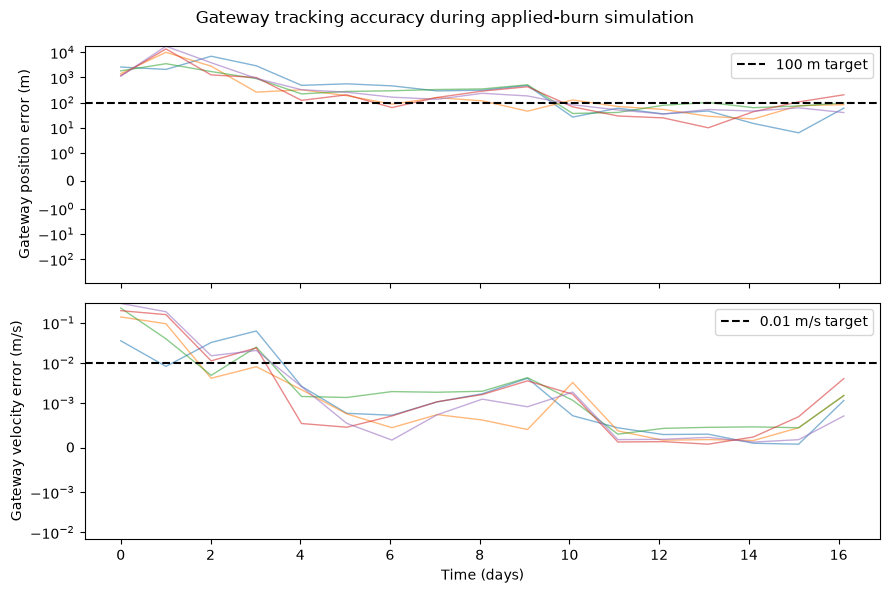

**Held-out test:** 5 episode(s). Position within 100 m: **40.0%** of decision epochs. Velocity within 0.01 m/s: **81.2%**. **Both limits simultaneously: 40.0%**. These are tracking-error metrics, not reference-departure metrics.

In [5]:
if (dataset_dir / "test.npz").exists():
    with np.load(dataset_dir / "test.npz") as d:
        t = np.array(d["decision_times_tu"]) * 375190.25852 / 86400
        p = np.array(d["gateway_tracking_position_error_km"])
        v = np.array(d["gateway_tracking_velocity_error_m_s"])
        both = (p <= 0.1) & (v <= 0.01)
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
        for i in range(min(len(p), 8)):
            ax1.plot(t, p[i]*1000, alpha=.55, linewidth=1)
            ax2.plot(t, v[i], alpha=.55, linewidth=1)
        ax1.axhline(100, linestyle="--", color="black", label="100 m target")
        ax2.axhline(.01, linestyle="--", color="black", label="0.01 m/s target")
        ax1.set_ylabel("Gateway position error (m)")
        ax2.set_ylabel("Gateway velocity error (m/s)")
        ax2.set_xlabel("Time (days)")
        ax1.legend()
        ax2.legend()
        ax1.set_yscale("symlog", linthresh=1)
        ax2.set_yscale("symlog", linthresh=.001)
        fig.suptitle("Gateway tracking accuracy during applied-burn simulation")
        plt.tight_layout()
        plt.show()
        display(Markdown(
            f"**Held-out test:** {len(p)} episode(s). Position within 100 m: **{100*np.mean(p<=.1):.1f}%** of decision epochs. "
            f"Velocity within 0.01 m/s: **{100*np.mean(v<=.01):.1f}%**. "
            f"**Both limits simultaneously: {100*np.mean(both):.1f}%**. "
            "These are tracking-error metrics, not reference-departure metrics."
        ))

## Observer maneuver labels and executed burns

Only the halo observer receives burn requests, feasible STM corrections, or applied impulses. Gateway is an unactuated tracking target. No Gateway maneuver totals or classifications should be interpreted as outcomes.

In [6]:
if (dataset_dir / "test.npz").exists():
    with np.load(dataset_dir / "test.npz") as d:
        lines = ["| Spacecraft | Decisions | Requested | Feasible requested | Rejected requested | Nonzero applied-burn records |", "|---|---:|---:|---:|---:|---:|"]
        for name in ("observer",):
            requested = np.asarray(d[name + "_maneuver_required"], dtype=bool)
            valid = np.asarray(d[name + "_maneuver_valid"], dtype=bool)
            applied = np.linalg.norm(d[name + "_applied_delta_v_rotating_m_s"], axis=-1) > 0
            lines.append(f"| {name.title()} | {requested.size} | {requested.sum()} | {(requested & valid).sum()} | {(requested & ~valid).sum()} | {applied.sum()} |")
        display(Markdown("\n".join(lines)))
        display(Markdown("The applied-burn count reflects **saved nonzero records**, not necessarily distinct commands when multiple impulses occur between decision epochs."))

| Spacecraft | Decisions | Requested | Feasible requested | Rejected requested | Nonzero applied-burn records |
|---|---:|---:|---:|---:|---:|
| Observer | 85 | 14 | 14 | 0 | 14 |

The applied-burn count reflects **saved nonzero records**, not necessarily distinct commands when multiple impulses occur between decision epochs.

## Observer maneuver learning results

Held-out observer precision/recall/F1, Δv RMSE, and teacher-forced delay accuracy are offline imitation metrics, not station-keeping success. Gateway has no maneuver predictor; its optical tracking results are above.

In [7]:
metrics_path = ROOT / "results/narx_two_stage/metrics.json"
if metrics_path.exists():
    metrics = json.loads(metrics_path.read_text())
    lines = ["| Spacecraft | Split | F1 | Precision | Recall | Δv RMSE (m/s) | Delay accuracy |", "|---|---|---:|---:|---:|---:|---:|"]
    for name, result in metrics.items():
        if name != "observer":
            continue
        for split in ("validation", "test"):
            m = result.get(split)
            if m is None:
                continue
            rmse = "N/A" if m["delta_v_rmse_m_s"] is None else f'{m["delta_v_rmse_m_s"]:.5f}'
            delay = "N/A" if m["burn_delay_class_accuracy_teacher_forced"] is None else f'{100*m["burn_delay_class_accuracy_teacher_forced"]:.1f}%'
            lines.append(f'| {name.title()} | {split} | {m["maneuver_f1"]:.3f} | {m["maneuver_precision"]:.3f} | {m["maneuver_recall"]:.3f} | {rmse} | {delay} |')
    display(Markdown("\n".join(lines)))
else:
    display(Markdown("**Learned-model scores have not been generated in this checkout.** Run `python scripts/run_two_stage_narx.py` to generate Monte Carlo data and evaluate the two-stage predictor, then rerun this notebook. No numerical learning performance is assumed."))

| Spacecraft | Split | F1 | Precision | Recall | Δv RMSE (m/s) | Delay accuracy |
|---|---|---:|---:|---:|---:|---:|
| Observer | validation | 0.714 | 0.833 | 0.625 | 0.25521 | 75.0% |
| Observer | test | 0.533 | 0.667 | 0.444 | 0.30780 | 77.8% |